Shape before cleaning: (3000, 5)
Shape after cleaning: (2786, 5)

Sales by region:
 Region
Central    150237.35
East       173588.30
South      102016.68
West       210852.20
Name: Sales, dtype: float64

Sales by category:
 Category
Furniture          198290.22
Office Supplies    203098.52
Technology         235305.79
Name: Sales, dtype: float64


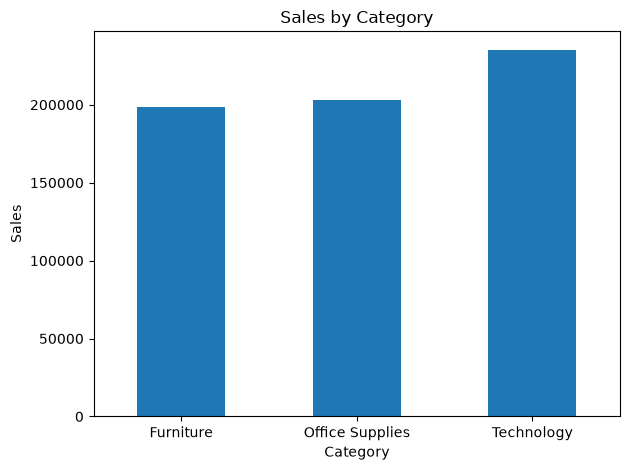

In [2]:
# Practical 7: Data Loading, Storage and File Formats
# Aim: Load sales data from CSV, Excel and JSON files, clean and combine it,
# summarize the sales and visualize them.
# Files: sales.csv, sales.xlsx, sales.json
import openpyxl
import pandas as pd
import matplotlib.pyplot as plt

csv_df = pd.read_csv("sales.csv")
excel_df = pd.read_excel("sales.xlsx")
json_df = pd.read_json("sales.json")

frames = [csv_df, excel_df, json_df]
for f in frames:
    f.columns = f.columns.str.strip().str.replace(" ", "_")

df = pd.concat(frames, ignore_index=True)
print("Shape before cleaning:", df.shape)

df = df.drop_duplicates()
df["Sales"] = pd.to_numeric(df["Sales"], errors="coerce")
df["Quantity"] = pd.to_numeric(df["Quantity"], errors="coerce")
df = df.dropna(subset=["Sales", "Region", "Category"])
df["Quantity"] = df["Quantity"].fillna(0)
print("Shape after cleaning:", df.shape)

print("\nSales by region:\n", df.groupby("Region")["Sales"].sum().round(2))
category_sales = df.groupby("Category")["Sales"].sum()
print("\nSales by category:\n", category_sales.round(2))

category_sales.plot(kind="bar", title="Sales by Category")
plt.ylabel("Sales")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

df.to_csv("cleaned_sales.csv", index=False)
df.to_excel("cleaned_sales.xlsx", index=False)